# Практична робота 5. Статистична обробка результатів обчислювального експерименту
**Виконав:** Кузьмук В. І., КНм-26.
Порівнюються **Алгоритм A** — гібрид з евристичними параметрами CVMaster (spaCy, аспекти 0.5/0.3/0.2, шар правил α = 1) та
**Алгоритм B** — калібрований варіант: параметри (α, ваги аспектів) обираються на даних за схемою leave-one-out —
для кожного CV конфігурація обирається за іншими 29 CV, тож оцінка B не є оптимістично зміщеною.
Одиниця спостереження — резюме (30 незалежних CV з еталонним ранжуванням 5 вакансій); для часових метрик — 30 повторних прогонів.

In [1]:
import sys, time, warnings; warnings.filterwarnings('ignore'); sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.metrics import (confusion_matrix, classification_report, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)
from cvmatch.experiment import *
sns.set_theme(style='whitegrid'); ALPHA = 0.05
v, cvs, ann, cons, corpus = setup('../data/raw')
CFG = {'A': dict(kind='spacy', use_aspects=True, use_rules=True, weights=(0.5,0.3,0.2), alpha=1.0),
       'B': dict(kind='spacy', use_aspects=True, use_rules=False, weights=(0.34,0.33,0.33), alpha=0.0),
       'M0': dict(kind='tfidf', use_aspects=False, use_rules=False)}

## Етап 1. Логи експерименту та описова статистика

In [2]:
res = {}
for k in ['A', 'M0']:
    d, m, S = evaluate(CFG[k], v, cvs, cons, corpus); d['alg'] = k; res[k] = (d, m, S)
# Leave-one-out калібрування B: сітка α × ваги, вибір за 29 CV, оцінювання на відкладеному CV
GRID = [dict(kind='spacy', use_aspects=True, use_rules=a > 0, alpha=a, weights=w)
        for a in [0, 0.25, 0.5, 0.75, 1.0] for w in [(1,0,0), (0.5,0.3,0.2), (0.34,0.33,0.33), (0.3,0.5,0.2), (0.3,0.2,0.5)]]
G = [evaluate(g, v, cvs, cons, corpus) for g in GRID]
R = np.array([g[0].set_index('cv_id').spearman.reindex(LABELED).values for g in G])      # конфігурації × CV
rowsB, S_B, chosen = [], {}, []
for n, i in enumerate(LABELED):
    others = [x for x in range(len(LABELED)) if x != n]
    c = int(np.argmax(R[:, others].mean(1))); chosen.append(c)
    rowsB.append(G[c][0].set_index('cv_id').loc[i].to_dict() | dict(cv_id=i))
    S_B.update({(i, j): G[c][2][(i, j)] for j in v.vac_idx})
dB = pd.DataFrame(rowsB); dB['alg'] = 'B'
c_mode = max(set(chosen), key=chosen.count); CFG['B'] = GRID[c_mode]
print('Обрані LOO-конфігурації (частота):', pd.Series([str((GRID[c]['alpha'], GRID[c]['weights'])) for c in chosen]).value_counts().to_dict())
res['B'] = (dB, G[c_mode][1], S_B)
q = pd.concat([res['A'][0], res['B'][0]])
# Часова метрика: 30 повторних прогонів скорингу 150 пар для кожного алгоритму
lat = []
for run in range(30):
    for k in 'AB':
        m = res[k][1]; t0 = time.perf_counter(); m.score_matrix(LABELED); lat.append(dict(run=run, alg=k, latency_ms=m.latency_ms))
lat = pd.DataFrame(lat)
q.to_csv('../results/pr5_per_cv.csv', index=False); lat.to_csv('../results/pr5_latency_runs.csv', index=False)
def iqr(x): return x.quantile(.75) - x.quantile(.25)
desc = pd.concat([q.groupby('alg')[['spearman','ndcg5','top1']].agg(['mean','median','std',iqr]),
                  lat.groupby('alg')[['latency_ms']].agg(['mean','median','std',iqr])], axis=1).T.round(4)
desc

Обрані LOO-конфігурації (частота): {'(0, (0.5, 0.3, 0.2))': 25, '(0, (0.34, 0.33, 0.33))': 3, '(0, (0.3, 0.2, 0.5))': 2}


alg                     A       B
spearman   mean   -0.1927  0.1318
           median -0.3563  0.2618
           std     0.4637  0.4670
           iqr     0.7246  0.7265
ndcg5      mean    0.8251  0.8821
           median  0.8095  0.9009
           std     0.1020  0.0877
           iqr     0.1721  0.1026
top1       mean    0.2000  0.2333
           median  0.0000  0.0000
           std     0.4068  0.4302
           iqr     0.0000  0.0000
latency_ms mean    0.0565  0.0206
           median  0.0481  0.0173
           std     0.0149  0.0062
           iqr     0.0144  0.0061

## Етап 2. Перевірка нормальності (Шапіро–Уїлк, Q-Q plot)

In [3]:
norm = []
for metric, df in [('spearman', q), ('latency_ms', lat)]:
    for alg in 'AB':
        W, p = stats.shapiro(df[df.alg==alg][metric]); norm.append(dict(metric=metric, alg=alg, W=W, p_value=p, normal=p > ALPHA))
    a = df[df.alg=='A'].sort_values(df.columns[0])[metric].values; b = df[df.alg=='B'].sort_values(df.columns[0])[metric].values
    W, p = stats.shapiro(a - b); norm.append(dict(metric=metric, alg='різниця A−B', W=W, p_value=p, normal=p > ALPHA))
norm = pd.DataFrame(norm); norm.round(4)

,metric,alg,W,p_value,normal
0,spearman,A,0.9567,0.2541,True
1,spearman,B,0.9221,0.0305,False
2,spearman,різниця A−B,0.9574,0.2647,True
3,latency_ms,A,0.6988,0.0000,False
4,latency_ms,B,0.6868,0.0000,False
5,latency_ms,різниця A−B,0.8093,0.0001,False


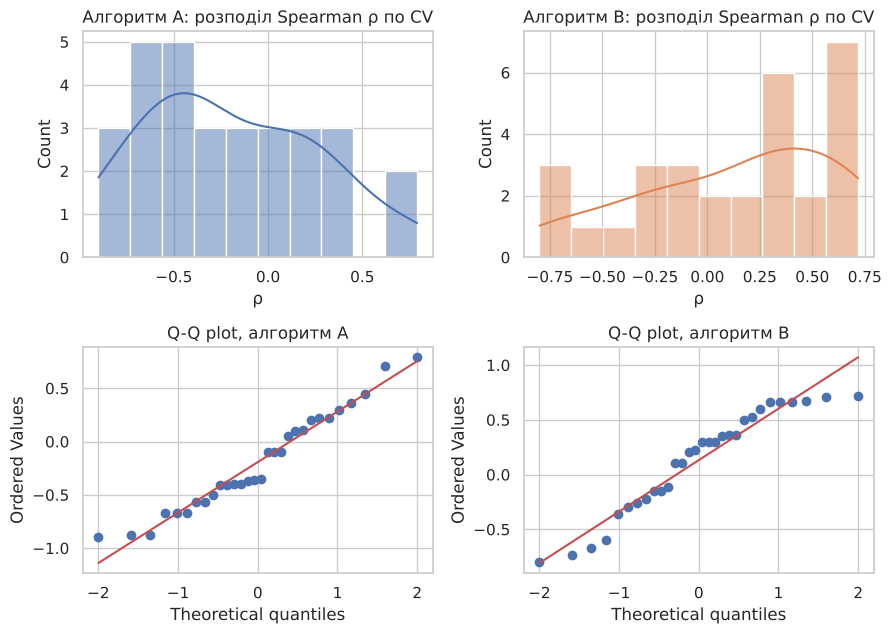

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(9, 6.5))
for j, alg in enumerate('AB'):
    x = q[q.alg==alg].spearman
    sns.histplot(x, bins=10, kde=True, ax=ax[0, j], color=['#4C72B0','#DD8452'][j])
    ax[0, j].set(title=f'Алгоритм {alg}: розподіл Spearman ρ по CV', xlabel='ρ')
    stats.probplot(x, dist='norm', plot=ax[1, j]); ax[1, j].set_title(f'Q-Q plot, алгоритм {alg}')
plt.tight_layout(); plt.savefig('../figures/pr5_normality.png', dpi=200); plt.show()

## Етап 3. Порівняльне статистичне тестування (парні вибірки)

In [5]:
tests = []
for metric, df, key in [('spearman', q, 'cv_id'), ('ndcg5', q, 'cv_id'), ('latency_ms', lat, 'run')]:
    a = df[df.alg=='A'].sort_values(key)[metric].values; b = df[df.alg=='B'].sort_values(key)[metric].values
    both = norm.query('metric==@metric and alg in ["A","B"]').normal.all() if metric in set(norm.metric) else False
    if both: name, (st, p) = 'парний t-критерій Стьюдента', stats.ttest_rel(a, b)
    else:    name, (st, p) = 'критерій Вілкоксона', stats.wilcoxon(a, b)
    dz = (b - a).mean() / (b - a).std(ddof=1)
    boot = [np.mean(np.random.default_rng(i).choice(b - a, len(a))) for i in range(5000)]
    tests.append(dict(metric=metric, test=name, statistic=st, p_value=p, mean_A=a.mean(), mean_B=b.mean(),
                      diff_B_minus_A=(b-a).mean(), ci95_low=np.percentile(boot, 2.5), ci95_high=np.percentile(boot, 97.5),
                      cohen_dz=dz, decision='відхиляємо H0' if p <= ALPHA else 'не відхиляємо H0'))
tests = pd.DataFrame(tests); tests.to_csv('../results/pr5_tests.csv', index=False); tests.round(4)

,metric,test,statistic,p_value,mean_A,mean_B,diff_B_minus_A,ci95_low,ci95_high,cohen_dz,decision
0,spearman,критерій Вілкоксона,107.0,0.0288,-0.1927,0.1318,0.3245,0.0718,0.5788,0.4460,відхиляємо H0
1,ndcg5,критерій Вілкоксона,81.0,0.0032,0.8251,0.8821,0.0570,0.0154,0.0954,0.4968,відхиляємо H0
2,latency_ms,критерій Вілкоксона,0.0,0.0000,0.0565,0.0206,-0.0359,-0.0393,-0.0328,-3.9298,відхиляємо H0


## Етап 4. Матриця помилок і метрики класифікації
Бінаризація: пара «CV–вакансія» **релевантна**, якщо консенсусна позиція ≤ 2 (вакансія у топ-2 для цього CV).
Прогноз: дві вакансії з найвищим балом для кожного CV — «релевантні». Для ROC-AUC бал z-нормалізується всередині CV.

In [6]:
def pairs(S):
    P = cons[cons.cv_id.isin(LABELED)].copy(); P['raw'] = [S[(i, j)] for i, j in zip(P.cv_id, P.vac_idx)]
    # бали порівнянні лише в межах одного CV, тому для ROC-AUC використовується z-нормалізація всередині CV
    P['score'] = P.groupby('cv_id').raw.transform(lambda x: (x - x.mean()) / (x.std(ddof=0) + 1e-9))
    P['y_true'] = (P.pos <= 2).astype(int)
    P['y_pred'] = P.groupby('cv_id').score.rank(ascending=False, method='first').le(2).astype(int)
    return P
PB = pairs(res['B'][2]); y, yp = PB.y_true.values, PB.y_pred.values
cm = confusion_matrix(y, yp); print(pd.DataFrame(cm, index=['нерелев.','релев.'], columns=['прогноз: нерелев.','прогноз: релев.']))
print(classification_report(y, yp, target_names=['нерелевантна','релевантна'], digits=4))
mets = {'Precision (macro)': precision_score(y, yp, average='macro'), 'Recall (macro)': recall_score(y, yp, average='macro'),
        'F1 (macro)': f1_score(y, yp, average='macro'), 'Precision (weighted)': precision_score(y, yp, average='weighted'),
        'Recall (weighted)': recall_score(y, yp, average='weighted'), 'F1 (weighted)': f1_score(y, yp, average='weighted'),
        'ROC-AUC': roc_auc_score(y, PB.score)}
pd.Series(mets).round(4)

          прогноз: нерелев.  прогноз: релев.
нерелев.                 67               43
релев.                   23               17
              precision    recall  f1-score   support

нерелевантна     0.7444    0.6091    0.6700       110
  релевантна     0.2833    0.4250    0.3400        40

    accuracy                         0.5600       150
   macro avg     0.5139    0.5170    0.5050       150
weighted avg     0.6215    0.5600    0.5820       150



Precision (macro)       0.5139
Recall (macro)          0.5170
F1 (macro)              0.5050
Precision (weighted)    0.6215
Recall (weighted)       0.5600
F1 (weighted)           0.5820
ROC-AUC                 0.4739
dtype: float64

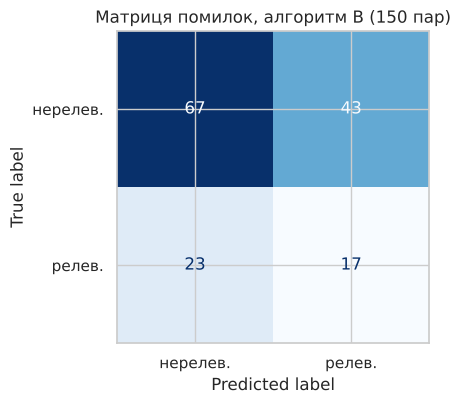

In [7]:
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay(cm, display_labels=['нерелев.','релев.']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Матриця помилок, алгоритм B (150 пар)'); plt.tight_layout(); plt.savefig('../figures/pr5_confusion.png', dpi=200); plt.show()

## Етап 5. Наукова візуалізація

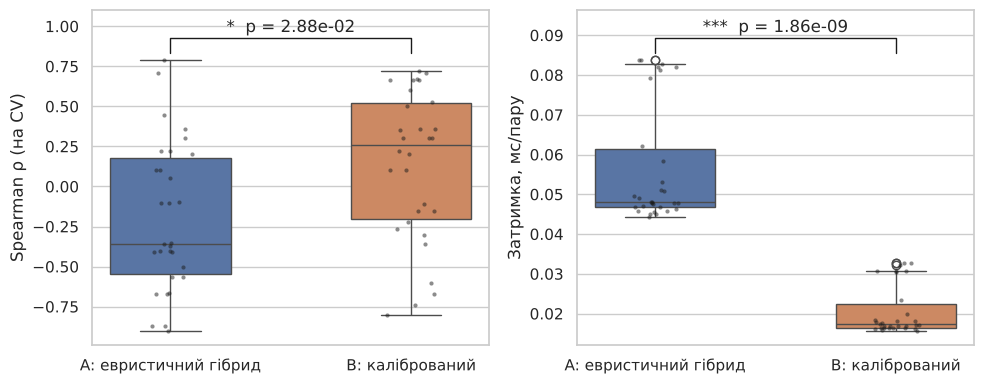

In [8]:
def stars(p): return '***' if p < .001 else '**' if p < .01 else '*' if p < .05 else 'n.s.'
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for j, (metric, df, lab) in enumerate([('spearman', q, 'Spearman ρ (на CV)'), ('latency_ms', lat, 'Затримка, мс/пару')]):
    sns.boxplot(data=df, x='alg', y=metric, ax=ax[j], palette=['#4C72B0','#DD8452'], width=.5, order=['A','B'])
    sns.stripplot(data=df, x='alg', y=metric, ax=ax[j], color='k', size=3, alpha=.5, order=['A','B'])
    p = tests.set_index('metric').loc[metric, 'p_value']; y0 = df[metric].max(); h = (df[metric].max() - df[metric].min()) * .08
    ax[j].plot([0,0,1,1], [y0+h*.3, y0+h, y0+h, y0+h*.3], c='k', lw=1)
    ax[j].text(.5, y0+h*1.1, f'{stars(p)}  p = {p:.2e}', ha='center', va='bottom')
    ax[j].set(xticks=[0,1], xticklabels=['A: евристичний гібрид', 'B: калібрований'], xlabel='', ylabel=lab); ax[j].set_ylim(top=y0+h*2.3)
plt.tight_layout(); plt.savefig('../figures/pr5_boxplot.png', dpi=200); plt.show()

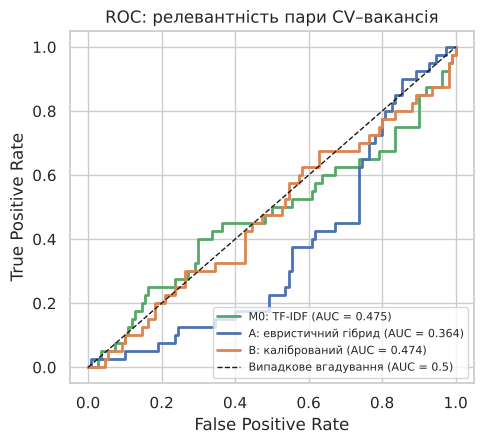

In [9]:
fig, ax = plt.subplots(figsize=(5, 4.6))
for k, lab, c in [('M0','M0: TF-IDF','#55A868'), ('A','A: евристичний гібрид','#4C72B0'), ('B','B: калібрований','#DD8452')]:
    P = pairs(res[k][2]); fpr, tpr, _ = roc_curve(P.y_true, P.score)
    ax.plot(fpr, tpr, c=c, lw=2, label=f'{lab} (AUC = {roc_auc_score(P.y_true, P.score):.3f})')
ax.plot([0,1], [0,1], 'k--', lw=1, label='Випадкове вгадування (AUC = 0.5)')
ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC: релевантність пари CV–вакансія')
ax.legend(loc='lower right', fontsize=8); plt.tight_layout(); plt.savefig('../figures/pr5_roc.png', dpi=200); plt.show()

## Самостійна робота. 3 алгоритми × 5 датасетів × 10 прогонів: Фрідман, Немені, Cohen's d
Датасет D_j (j = 1..5) — задача рекрутера «ранжувати 30 кандидатів для вакансії j» (метрика — Spearman ρ між балом і консенсусною релевантністю).
10 прогонів — бутстреп-вибірки 30 CV (seed = 0..9). Разом 50 блоків для тесту Фрідмана.

In [10]:
import scikit_posthocs as sp
ALGS = {'M0 (TF-IDF)': 'M0', 'A (гібрид)': 'A', 'B (калібр.)': 'B'}
rel = cons.set_index(['cv_id','vac_idx']).rel
rows = []
for j in v.vac_idx:
    for r in range(10):
        ids = np.random.default_rng(r).choice(LABELED, len(LABELED), replace=True)
        for name, k in ALGS.items():
            S = res[k][2]; s = [S[(i, j)] for i in ids]; t = [rel[(i, j)] for i in ids]
            rows.append(dict(dataset=f'D{j}', run=r, alg=name, rho=stats.spearmanr(s, t).correlation))
cvr = pd.DataFrame(rows); cvr.to_csv('../results/pr5_3algs_5datasets.csv', index=False)
mat = cvr.pivot_table(index='dataset', columns='alg', values='rho')[list(ALGS)]; mat.round(4)

alg,M0 (TF-IDF),A (гібрид),B (калібр.)
dataset,,,
D1,0.1121,-0.5376,-0.0870
D2,-0.0410,0.0488,0.0751
D3,-0.0528,0.0161,-0.2711
D4,-0.0986,0.0982,0.2428
D5,0.0142,-0.1803,0.0504


In [11]:
blocks = cvr.pivot_table(index=['dataset','run'], columns='alg', values='rho')[list(ALGS)]
chi2, p_fr = stats.friedmanchisquare(*[blocks[a] for a in ALGS])
chi2_5, p_fr5 = stats.friedmanchisquare(*[mat[a] for a in ALGS])
ranks = blocks.rank(axis=1, ascending=False).mean()
print(f'Фрідман (N = 50 блоків): chi2 = {chi2:.3f}, p = {p_fr:.3e}')
print(f'Фрідман (N = 5 датасетів, середні): chi2 = {chi2_5:.3f}, p = {p_fr5:.3e}')
print('Середні ранги (1 = найкращий):'); print(ranks.round(3))
nem = sp.posthoc_nemenyi_friedman(blocks.values); nem.index = nem.columns = list(ALGS)
print('Пост-хок Немені, p-values:'); nem.round(4)

Фрідман (N = 50 блоків): chi2 = 6.760, p = 3.405e-02
Фрідман (N = 5 датасетів, середні): chi2 = 1.200, p = 5.488e-01
Середні ранги (1 = найкращий):
alg
M0 (TF-IDF)    2.14
A (гібрид)     2.16
B (калібр.)    1.70
dtype: float64
Пост-хок Немені, p-values:


,M0 (TF-IDF),A (гібрид),B (калібр.)
M0 (TF-IDF),1.0000,0.9945,0.0712
A (гібрид),0.9945,1.0000,0.0558
B (калібр.),0.0712,0.0558,1.0000


In [12]:
from itertools import combinations
eff = []
for a1, a2 in combinations(ALGS, 2):
    diff = blocks[a2] - blocks[a1]; pooled = np.sqrt((blocks[a1].var(ddof=1) + blocks[a2].var(ddof=1)) / 2)
    eff.append(dict(pair=f'{a2} − {a1}', mean_diff=diff.mean(), cohen_d=diff.mean()/pooled, nemenyi_p=nem.loc[a1, a2]))
eff = pd.DataFrame(eff); eff.to_csv('../results/pr5_effects.csv', index=False); eff.round(4)

,pair,mean_diff,cohen_d,nemenyi_p
0,A (гібрид) − M0 (TF-IDF),-0.0978,-0.4120,0.9945
1,B (калібр.) − M0 (TF-IDF),0.0153,0.0774,0.0712
2,B (калібр.) − A (гібрид),0.1130,0.4316,0.0558


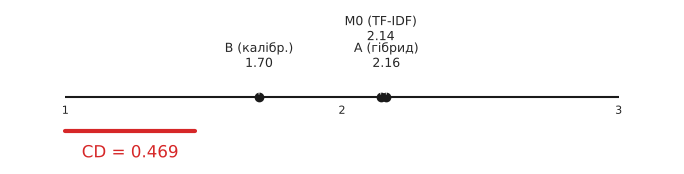

In [13]:
k, N = len(ALGS), len(blocks); CD = 2.343 * np.sqrt(k * (k + 1) / (6 * N))     # q_0.05(k=3) = 2.343 (Демшар, 2006)
fig, ax = plt.subplots(figsize=(7, 1.9)); r = ranks.sort_values()
ax.hlines(0, 1, k, color='k'); ax.set_xlim(.8, k + .2); ax.set_ylim(-1, 1.3); ax.axis('off')
for i, (alg, rk) in enumerate(r.items()):
    ax.plot(rk, 0, 'o', c='k'); ax.annotate(f'{alg}\n{rk:.2f}', (rk, 0), (rk, .45 + .4*(i % 2)), ha='center', fontsize=9, arrowprops=dict(arrowstyle='-', lw=.6))
ax.plot([1, 1 + CD], [-.5, -.5], c='tab:red', lw=3); ax.text(1 + CD/2, -.9, f'CD = {CD:.3f}', ha='center', color='tab:red')
for x in range(1, k + 1): ax.text(x, -.25, str(x), ha='center', fontsize=8)
plt.tight_layout(); plt.savefig('../figures/pr5_cd.png', dpi=200); plt.show()